<a href="https://colab.research.google.com/github/hnkessler/pothole-detection/blob/main/Henry_Kessler_pothole_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Import Relevant Libraries and Mount Drive

In [3]:
# Import relevant libraries including TensorFlow and Keras
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import time
from scipy import ndimage
from tqdm import tqdm
from IPython import display
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras import layers, models

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Import Data

In [5]:
# Unzip dataset contents
!unzip -q -o "/content/drive/MyDrive/pothole-detection-dataset.zip" -d "/content/data"

In [6]:
# Load Data
data_directory = "/content/data/Neha Pothole and normal dataset"

classifiers = ["Normal", "Pothole"]

image_size = int(128)

def list_images(folder):
    return sorted(f for f in os.listdir(folder) if f.lower())

num_examples = sum(len(list_images(os.path.join(data_directory, c))) for c in classifiers)

data = np.zeros((num_examples, image_size, image_size, 3), dtype=float, order='C')
data_canny = np.zeros((num_examples, image_size, image_size), dtype=float, order='C')
data_laplacian = np.zeros((num_examples, image_size, image_size), dtype=float, order='C')
data_gray = np.zeros((num_examples, image_size, image_size), dtype=float, order='C')

data_gaussian = np.zeros((num_examples, image_size, image_size), dtype=float, order='C')

y = np.zeros(num_examples, dtype=float, order='C')

i = 0

for category in classifiers:

        path = os.path.join(data_directory,category)
        class_num = classifiers.index(category)

        for img in tqdm(list_images(path)):

            img_array = cv2.imread(os.path.join(path,img))  # convert to array

            img_gray = cv2.imread(os.path.join(path,img), cv2.IMREAD_GRAYSCALE)  # convert to array
            img_resized_gray = cv2.resize(img_gray, (128,128))

            img_resized = cv2.cvtColor(cv2.resize(img_array, (128,128)), cv2.COLOR_BGR2RGB)

            img_canny = cv2.Canny(img_resized_gray, 100, 150)
            img_laplacian = cv2.Laplacian(img_resized_gray, cv2.CV_64F)

            # Add greyscale data to numpy array
            data_laplacian[i] = img_laplacian
            data_canny[i] = img_canny
            data_gray[i] = img_resized_gray

            data[i] = img_resized

            # Label
            y[i] = int(class_num)
            i += 1

# Create Gaussian High Pass
for i in range(num_examples):
    low = ndimage.gaussian_filter(data_gray[i], 3)
    img_gaussian = data_gray[i] - low

    data_gaussian[i] = img_gaussian

print("\n", "Data successfully loaded")

# 0 = No Pothole, 1 = Pothole

100%|██████████| 2500/2500 [00:22<00:00, 111.83it/s]



 Data successfully loaded


In [7]:
# Make sure everything was properly converted, no zero numpy array
for i in range(num_examples):
  all_zeros = not np.any(data[i])

  if all_zeros == 1:
    print("ZERO")

### Pre-Processing Visualization (Optional)

(np.float64(-0.5), np.float64(127.5), np.float64(127.5), np.float64(-0.5))

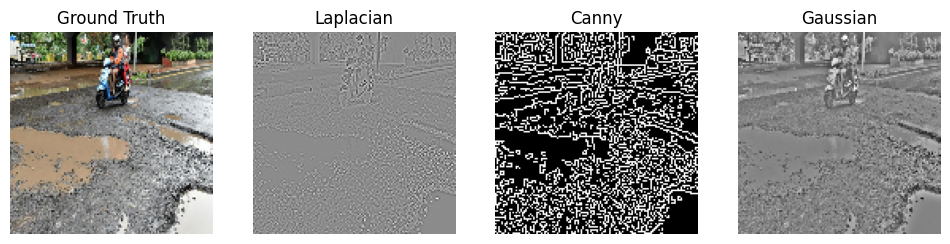

In [8]:
# Create subplots showing the ground truth and preprocessed images
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
im_index = 2600

# Ground Truth
axes[0].imshow((data[im_index]).astype(np.uint8))
axes[0].set_title('Ground Truth')
axes[0].axis('off')

# Laplacian
axes[1].imshow(data_laplacian[im_index], cmap='gray')  # graph it
axes[1].set_title('Laplacian')
axes[1].axis('off')

# Canny
axes[2].imshow(data_canny[im_index], cmap='gray')  # graph it
axes[2].set_title('Canny')
axes[2].axis('off')

# Gaussian High Pass
low = ndimage.gaussian_filter(data_gray[im_index], 3)
high = data_gray[im_index] - low

axes[3].imshow(high, cmap = 'gray')
axes[3].set_title('Gaussian')
axes[3].axis('off')


### Train/Validation/Test Split + Normalization + Dataset

In [9]:
# Train/Val/Test data split
X_train, X_test, y_train, y_test = train_test_split(data, y, test_size=0.20, random_state=1)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=1)

In [10]:
# Normalize Data by X_train with a mean of 0. Dont include test data determining normalization
mean_image = np.mean(X_train, axis = 0)

X_train -= mean_image
X_test -= mean_image
X_val -= mean_image

data_shape = X_train.shape # Stores the original shape before we convert to a dataset

In [11]:
batch_size = 25

# One hot encode labels to 2 columns
y_train_converted = tf.keras.utils.to_categorical(y_train, num_classes = 2)
y_val_converted = tf.keras.utils.to_categorical(y_val, num_classes = 2)
y_test_converted = tf.keras.utils.to_categorical(y_test, num_classes = 2)

# Create datasets of normalized data. Combine data and labels so they stay together when shuffling
train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train_converted))
val_dataset = tf.data.Dataset.from_tensor_slices((X_val, y_val_converted))

# Batch + Shuffle. Shuffle so that we are mixing images with and without potholes
train_dataset = train_dataset.shuffle(num_examples).batch(batch_size)
val_dataset = val_dataset.shuffle(num_examples).batch(batch_size)

### Model #1 (FCN)

In [12]:
# Model #1 (FCN)
model_FCN = models.Sequential()

model_FCN.add(tf.keras.Input(shape=data_shape[1:]))
model_FCN.add(layers.Flatten())

model_FCN.add(layers.Dense(50)) # Fully Connected
model_FCN.add(layers.BatchNormalization())
model_FCN.add(layers.ReLU())
model_FCN.add(layers.Dropout(0.3))

model_FCN.add(layers.Dense(50)) # Fully Connected
model_FCN.add(layers.BatchNormalization())
model_FCN.add(layers.ReLU())
model_FCN.add(layers.Dropout(0.3))

model_FCN.add(layers.Dense(50)) # Fully Connected
model_FCN.add(layers.BatchNormalization())
model_FCN.add(layers.ReLU())
model_FCN.add(layers.Dropout(0.3))

model_FCN.add(layers.Dense(2)) # Output (logits)

model_FCN.summary() # Summarize model

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 50)             │     2,457,650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 50)             │           200 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │         2,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 50)             │           200 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 50)             │         2,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 50)             │           200 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,463,452 (9.40 MB)

 Trainable params: 2,463,152 (9.40 MB)

 Non-trainable params: 300 (1.17 KB)

### Model #2 (CNN 1)

In [13]:
# Model #2 (CNN1)
model_CNN1 = models.Sequential()
model_CNN1.add(tf.keras.Input(shape=(data_shape[1:])))

model_CNN1.add(layers.Conv2D(64, (3,3), strides=(1,1)))
model_CNN1.add(layers.BatchNormalization())
model_CNN1.add(layers.ReLU())
model_CNN1.add(layers.Dropout(0.2))

model_CNN1.add(layers.Conv2D(64, (3,3), strides=(2,2)))
model_CNN1.add(layers.BatchNormalization())
model_CNN1.add(layers.ReLU())

model_CNN1.add(layers.Conv2D(64, (3,3), strides=(2,2)))
model_CNN1.add(layers.BatchNormalization())
model_CNN1.add(layers.ReLU())

model_CNN1.add(layers.Conv2D(32, (3,3), strides=(2,2)))
model_CNN1.add(layers.BatchNormalization())
model_CNN1.add(layers.ReLU())

model_CNN1.add(layers.AveragePooling2D(pool_size=(2,2)))
model_CNN1.add(layers.Flatten())

model_CNN1.add(layers.Dense(64))
model_CNN1.add(layers.ReLU())
model_CNN1.add(layers.Dropout(0.2))

model_CNN1.add(layers.Dense(64))
model_CNN1.add(layers.ReLU())
model_CNN1.add(layers.Dropout(0.2))

model_CNN1.add(layers.Dense(2))

model_CNN1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 126, 126, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 126, 126, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 126, 126, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 62, 62, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 62, 62, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 30, 30, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 30, 30, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 14, 14, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 7, 7, 32)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_8 (ReLU)                  │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 199,714 (780.13 KB)

 Trainable params: 199,266 (778.38 KB)

 Non-trainable params: 448 (1.75 KB)

### Model #3 (CNN 2)

In [14]:
# Model #3 (CNN2)
model_CNN2 = models.Sequential()

model_CNN2.add(tf.keras.Input(shape=(data_shape[1:])))
model_CNN2.add(layers.Conv2D(32, 3, strides=(1,1), padding='same'))
model_CNN2.add(layers.BatchNormalization())
model_CNN2.add(layers.ReLU())

model_CNN2.add(layers.Conv2D(64, 3, strides=(1,1), padding='same'))
model_CNN2.add(layers.BatchNormalization())
model_CNN2.add(layers.ReLU())

model_CNN2.add(layers.MaxPooling2D(2, strides=(2,2)))
model_CNN2.add(layers.Conv2D(128, 3, strides=(1,1), padding='same'))
model_CNN2.add(layers.BatchNormalization())
model_CNN2.add(layers.ReLU())

model_CNN2.add(layers.Conv2D(256, 3, strides=(1,1), padding='same'))
model_CNN2.add(layers.BatchNormalization())
model_CNN2.add(layers.ReLU())

model_CNN2.add(layers.MaxPooling2D(2, strides=(2,2)))
model_CNN2.add(layers.Conv2D(256, 3, strides=(1,1), padding='same'))
model_CNN2.add(layers.BatchNormalization())
model_CNN2.add(layers.ReLU())

model_CNN2.add(layers.MaxPooling2D(2, strides=(2,2)))
model_CNN2.add(layers.Conv2D(256, 3, strides=(1,1), padding='same'))
model_CNN2.add(layers.BatchNormalization())
model_CNN2.add(layers.ReLU())

model_CNN2.add(layers.Conv2D(256, 3, strides=(1,1), padding='same'))
model_CNN2.add(layers.BatchNormalization())
model_CNN2.add(layers.ReLU())

model_CNN2.add(layers.MaxPooling2D(2, strides=(2,2)))
model_CNN2.add(layers.Conv2D(512, 3, strides=(2,2), padding='same'))
model_CNN2.add(layers.BatchNormalization())
model_CNN2.add(layers.ReLU())

model_CNN2.add(layers.MaxPooling2D(2, strides=(2,2)))
model_CNN2.add(layers.Conv2D(512, 3, strides=(1,1), padding='same'))
model_CNN2.add(layers.BatchNormalization())
model_CNN2.add(layers.ReLU())

model_CNN2.add(layers.Flatten())
model_CNN2.add(layers.Dense(1000, activation='relu'))
model_CNN2.add(layers.Dropout(0.5))
model_CNN2.add(layers.Dense(1000, activation='relu'))
model_CNN2.add(layers.Dropout(0.5))

model_CNN2.add(layers.Dense(2))
model_CNN2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_9 (ReLU)                  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_10 (ReLU)                 │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_11 (ReLU)                 │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 64, 64, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_12 (ReLU)                 │ (None, 64, 64, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_13 (ReLU)                 │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_14 (ReLU)                 │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 256)    │       590,08

 Total params: 8,759,714 (33.42 MB)

 Trainable params: 8,755,170 (33.40 MB)

 Non-trainable params: 4,544 (17.75 KB)

### Model #4 (VGG16 Model)

In [15]:
# VGG16 Model
model_VGG16 = models.Sequential()

model_VGG16.add(tf.keras.Input(shape=(data_shape[1:])))
model_VGG16.add(layers.Conv2D(64, 3, strides=(1,1), padding='same'))
model_VGG16.add(layers.ReLU())

model_VGG16.add(layers.Conv2D(64, 3, strides=(1,1), padding='same'))
model_VGG16.add(layers.ReLU())

model_VGG16.add(layers.MaxPooling2D(2, strides=(2,2)))
model_VGG16.add(layers.Conv2D(128, 3, strides=(1,1), padding='same'))
model_VGG16.add(layers.ReLU())

model_VGG16.add(layers.Conv2D(128, 3, strides=(1,1), padding='same'))
model_VGG16.add(layers.ReLU())

model_VGG16.add(layers.MaxPooling2D(2, strides=(2,2)))
model_VGG16.add(layers.Conv2D(256, 3, strides=(1,1), padding='same'))
model_VGG16.add(layers.ReLU())

model_VGG16.add(layers.Conv2D(256, 3, strides=(1,1), padding='same'))
model_VGG16.add(layers.ReLU())

model_VGG16.add(layers.Conv2D(256, 1, strides=(1,1), padding='same'))
model_VGG16.add(layers.ReLU())

model_VGG16.add(layers.MaxPooling2D(2, strides=(2,2)))
model_VGG16.add(layers.Conv2D(512, 3, strides=(1,1), padding='same'))
model_VGG16.add(layers.ReLU())

model_VGG16.add(layers.Conv2D(512, 3, strides=(1,1), padding='same'))
model_VGG16.add(layers.ReLU())

model_VGG16.add(layers.Conv2D(512, 1, strides=(1,1), padding='same'))
model_VGG16.add(layers.ReLU())

model_VGG16.add(layers.MaxPooling2D(2, strides=(2,2)))
model_VGG16.add(layers.Conv2D(512, 3, strides=(1,1), padding='same'))
model_VGG16.add(layers.ReLU())

model_VGG16.add(layers.Conv2D(512, 3, strides=(1,1), padding='same'))
model_VGG16.add(layers.ReLU())

model_VGG16.add(layers.Conv2D(512, 1, strides=(1,1), padding='same'))
model_VGG16.add(layers.ReLU())

model_VGG16.add(layers.MaxPooling2D(2, strides=(2,2)))

model_VGG16.add(layers.Flatten())
model_VGG16.add(layers.Dense(4096, activation='relu'))
model_VGG16.add(layers.Dropout(0.5))
model_VGG16.add(layers.Dense(4096, activation='relu'))
model_VGG16.add(layers.Dropout(0.5))

model_VGG16.add(layers.Dense(2))

model_VGG16.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_13 (Conv2D)              │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_18 (ReLU)                 │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 128, 128, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_19 (ReLU)                 │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_20 (ReLU)                 │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 64, 64, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_21 (ReLU)                 │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_22 (ReLU)                 │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_23 (ReLU)                 │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 32, 32, 256)    │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_24 (ReLU)                 │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_25 (ReLU)                 │ (None, 16, 16, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_26 (ReLU)                 │ (None, 16, 16, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 16, 16, 512)    │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_27 (ReLU)                 │ (None, 16, 16, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 8, 8, 512)      │     2,359,80

 Total params: 60,344,130 (230.19 MB)

 Trainable params: 60,344,130 (230.19 MB)

 Non-trainable params: 0 (0.00 B)

### Train Model

Epoch 1/100
120/120 - 12s - 96ms/step - accuracy: 0.5660 - loss: 0.7954 - val_accuracy: 0.7230 - val_loss: 0.6251
Epoch 2/100
120/120 - 1s - 6ms/step - accuracy: 0.6337 - loss: 0.7001 - val_accuracy: 0.7600 - val_loss: 0.5492
Epoch 3/100
120/120 - 1s - 6ms/step - accuracy: 0.6517 - loss: 0.6623 - val_accuracy: 0.7360 - val_loss: 0.5469
Epoch 4/100
120/120 - 1s - 6ms/step - accuracy: 0.6810 - loss: 0.6245 - val_accuracy: 0.7480 - val_loss: 0.5238
Epoch 5/100
120/120 - 1s - 6ms/step - accuracy: 0.7153 - loss: 0.5920 - val_accuracy: 0.7740 - val_loss: 0.4785
Epoch 6/100
120/120 - 1s - 6ms/step - accuracy: 0.7187 - loss: 0.5727 - val_accuracy: 0.8040 - val_loss: 0.4485
Epoch 7/100
120/120 - 1s - 6ms/step - accuracy: 0.7387 - loss: 0.5313 - val_accuracy: 0.7760 - val_loss: 0.4542
Epoch 8/100
120/120 - 1s - 6ms/step - accuracy: 0.7510 - loss: 0.5149 - val_accuracy: 0.7890 - val_loss: 0.4388
Epoch 9/100
120/120 - 1s - 6ms/step - accuracy: 0.7553 - loss: 0.5063 - val_accuracy: 0.7870 - val_los

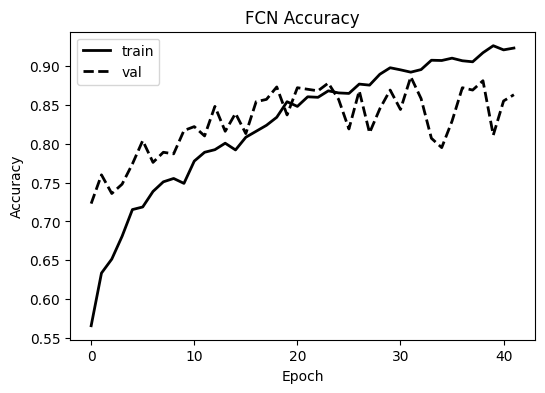

FCN final test set accuracy: 0.876
Epoch 1/100
120/120 - 20s - 168ms/step - accuracy: 0.7687 - loss: 0.4875 - val_accuracy: 0.7330 - val_loss: 0.4933
Epoch 2/100
120/120 - 2s - 18ms/step - accuracy: 0.8840 - loss: 0.2934 - val_accuracy: 0.9230 - val_loss: 0.1992
Epoch 3/100
120/120 - 2s - 18ms/step - accuracy: 0.9117 - loss: 0.2321 - val_accuracy: 0.9380 - val_loss: 0.1617
Epoch 4/100
120/120 - 2s - 18ms/step - accuracy: 0.9337 - loss: 0.1846 - val_accuracy: 0.9400 - val_loss: 0.1594
Epoch 5/100
120/120 - 2s - 18ms/step - accuracy: 0.9330 - loss: 0.1861 - val_accuracy: 0.9370 - val_loss: 0.1790
Epoch 6/100
120/120 - 2s - 18ms/step - accuracy: 0.9417 - loss: 0.1601 - val_accuracy: 0.9550 - val_loss: 0.1174
Epoch 7/100
120/120 - 2s - 18ms/step - accuracy: 0.9437 - loss: 0.1480 - val_accuracy: 0.9520 - val_loss: 0.1260
Epoch 8/100
120/120 - 2s - 18ms/step - accuracy: 0.9560 - loss: 0.1292 - val_accuracy: 0.9560 - val_loss: 0.1110
Epoch 9/100
120/120 - 2s - 18ms/step - accuracy: 0.9600 - l

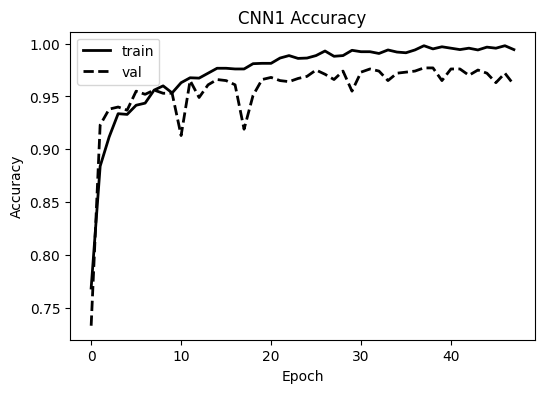

CNN1 final test set accuracy: 0.965
Epoch 1/100
120/120 - 41s - 343ms/step - accuracy: 0.8537 - loss: 0.3793 - val_accuracy: 0.8190 - val_loss: 0.3798
Epoch 2/100
120/120 - 7s - 56ms/step - accuracy: 0.9263 - loss: 0.2170 - val_accuracy: 0.9310 - val_loss: 0.1908
Epoch 3/100
120/120 - 7s - 56ms/step - accuracy: 0.9377 - loss: 0.1666 - val_accuracy: 0.9490 - val_loss: 0.1393
Epoch 4/100
120/120 - 7s - 56ms/step - accuracy: 0.9520 - loss: 0.1312 - val_accuracy: 0.9530 - val_loss: 0.1423
Epoch 5/100
120/120 - 7s - 56ms/step - accuracy: 0.9610 - loss: 0.1110 - val_accuracy: 0.8330 - val_loss: 0.4810
Epoch 6/100
120/120 - 7s - 56ms/step - accuracy: 0.9690 - loss: 0.0963 - val_accuracy: 0.9610 - val_loss: 0.0895
Epoch 7/100
120/120 - 7s - 56ms/step - accuracy: 0.9747 - loss: 0.0749 - val_accuracy: 0.9700 - val_loss: 0.0713
Epoch 8/100
120/120 - 7s - 56ms/step - accuracy: 0.9797 - loss: 0.0506 - val_accuracy: 0.9630 - val_loss: 0.0886
Epoch 9/100
120/120 - 7s - 56ms/step - accuracy: 0.9770 - 

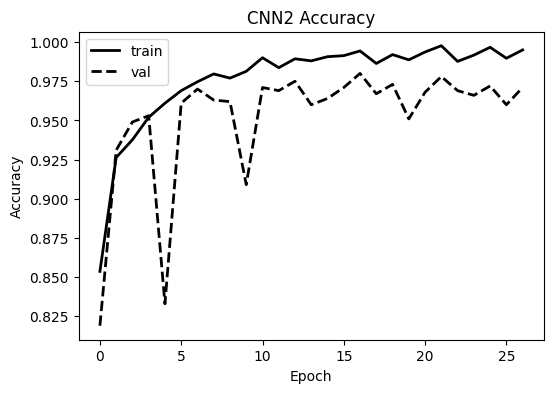

CNN2 final test set accuracy: 0.977
Epoch 1/100
120/120 - 39s - 328ms/step - accuracy: 0.6900 - loss: 0.6126 - val_accuracy: 0.6640 - val_loss: 0.6162
Epoch 2/100
120/120 - 8s - 68ms/step - accuracy: 0.8693 - loss: 0.3335 - val_accuracy: 0.9500 - val_loss: 0.1384
Epoch 3/100
120/120 - 8s - 67ms/step - accuracy: 0.9090 - loss: 0.2314 - val_accuracy: 0.9370 - val_loss: 0.1568
Epoch 4/100
120/120 - 8s - 67ms/step - accuracy: 0.9400 - loss: 0.1872 - val_accuracy: 0.9250 - val_loss: 0.2051
Epoch 5/100
120/120 - 8s - 68ms/step - accuracy: 0.9500 - loss: 0.1422 - val_accuracy: 0.9590 - val_loss: 0.1137
Epoch 6/100
120/120 - 8s - 66ms/step - accuracy: 0.9490 - loss: 0.1324 - val_accuracy: 0.9510 - val_loss: 0.1376
Epoch 7/100
120/120 - 8s - 68ms/step - accuracy: 0.9593 - loss: 0.1114 - val_accuracy: 0.9610 - val_loss: 0.1172
Epoch 8/100
120/120 - 8s - 67ms/step - accuracy: 0.9663 - loss: 0.0975 - val_accuracy: 0.9630 - val_loss: 0.1108
Epoch 9/100
120/120 - 8s - 66ms/step - accuracy: 0.9737 - 

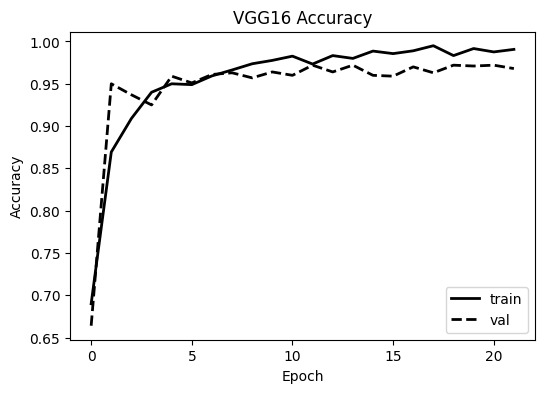

VGG16 final test set accuracy: 0.966


In [16]:
models_to_train = {
    'FCN':   model_FCN,
    'CNN1':  model_CNN1,
    'CNN2':  model_CNN2,
    'VGG16': model_VGG16,
}

learning_rate = 1e-4

training_results = {}
results = {}
os.makedirs('figures', exist_ok=True)

for name, model in models_to_train.items():
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate),
                  loss=tf.keras.losses.CategoricalCrossentropy(from_logits=True),
                  metrics=['accuracy'])

    early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True) # if 10 epochs lower validation accuracy in a row, stop training

    all_data = model.fit(train_dataset, epochs=100, validation_data=val_dataset, callbacks=[early_stop], verbose=2)

    training_results[name] = all_data

    # Plot training/validation accuracies
    plt.figure(figsize=(6, 4))
    plt.plot(all_data.history['accuracy'], color='black', linewidth=2, label='train')
    plt.plot(all_data.history['val_accuracy'], linestyle='--', color='black', linewidth=2, label='val')
    plt.title(f'{name} Accuracy'); plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()
    plt.savefig(f'figures/{name}.png')
    plt.show()

    # Print final test accuracy
    test_loss, test_acc = model.evaluate(X_test, y_test_converted, verbose=0)
    results[name] = test_acc
    print(f'{name} final test set accuracy: {test_acc:.3f}')

### Generative Adversarial Network (GAN)

In [17]:
batch_size = 64
gan_size = 64

pothole_images = data[y == 1].astype(np.uint8)
train_images = np.array([cv2.resize(img, (gan_size, gan_size)) for img in pothole_images], dtype='float32')
train_images = (train_images - 127.5) / 127.5 # Normalizes data between -1/1
train_dataset = tf.data.Dataset.from_tensor_slices(train_images).shuffle(num_examples).batch(batch_size, drop_remainder = True)

In [18]:
# Define generator/discriminator functions

# Generator
def create_generator(): # make_generator_model

    model = tf.keras.Sequential()
    model.add(tf.keras.Input(shape=(100,)))

    model.add(layers.Dense(4*4*512, use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.ReLU())
    model.add(layers.Reshape((4, 4, 512)))

    model.add(layers.UpSampling2D(2, interpolation='nearest'))
    model.add(layers.Conv2D(256, (3, 3), padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.ReLU())

    model.add(layers.UpSampling2D(2, interpolation='nearest'))
    model.add(layers.Conv2D(128, (3, 3), padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.ReLU())

    model.add(layers.UpSampling2D(2, interpolation='nearest'))
    model.add(layers.Conv2D(64, (3, 3), padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.ReLU())

    model.add(layers.UpSampling2D(2, interpolation='nearest'))
    model.add(layers.Conv2D(3, (3, 3), padding='same', activation='tanh'))

    return model

# Discriminator
def create_discriminator(): # make_discriminator_model

    model = tf.keras.Sequential()
    model.add(tf.keras.Input(shape=(gan_size, gan_size, 3)))

    model.add(layers.Conv2D(64, (4, 4), strides=(2, 2), padding='same'))
    model.add(layers.LeakyReLU(0.2))

    model.add(layers.Conv2D(128, (4, 4), strides=(2, 2), padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))

    model.add(layers.Conv2D(256, (4, 4), strides=(2, 2), padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))

    model.add(layers.Flatten())
    model.add(layers.Dropout(0.3))
    model.add(layers.Dense(1))

    return model

In [19]:
# Create discriminator/generator models
generator = create_generator()
discriminator = create_discriminator()

In [20]:
# Define loss functions

# Define loss
loss_fn = tf.keras.losses.BinaryCrossentropy(from_logits=True)

# Generator
def generator_loss(fake_output):
    return loss_fn(tf.ones_like(fake_output), fake_output)

# Discriminator
def discriminator_loss(real_output, fake_output):
    real_loss = loss_fn(tf.ones_like(real_output), real_output)
    fake_loss = loss_fn(tf.zeros_like(fake_output), fake_output)
    total_loss = real_loss + fake_loss
    return total_loss

In [21]:
def generate_and_save_images(model, epoch, test_input):
  predictions = model(test_input, training=False)
  images = (predictions.numpy() * 127.5 + 127.5).astype(np.uint8) # Unnormalize data

  fig = plt.figure(figsize=(10, 10))
  for i in range(images.shape[0]):
      plt.subplot(4, 4, i+1)
      plt.imshow(images[i])
      plt.axis('off')

  plt.axis('off')
  os.makedirs('figures/gan', exist_ok=True)
  plt.savefig('figures/gan/pothole_{:04d}.png'.format(epoch), bbox_inches='tight', pad_inches=0)
  plt.show()

In [22]:
generator_optimizer = tf.keras.optimizers.Adam(1e-4, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4, beta_1=0.5)

In [35]:
num_epochs = 250;
noise_dimension = 100;
num_samples = 16
seed = tf.random.normal([num_samples, noise_dimension])

In [26]:
# Define training functions
@tf.function
def train_step(images):
    noise = tf.random.normal([batch_size, noise_dimension])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
      generated_images = generator(noise, training=True)

      real_output = discriminator(images, training=True)
      fake_output = discriminator(generated_images, training=True)

      gen_loss = generator_loss(fake_output)
      disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

os.makedirs('checkpoints', exist_ok=True) # Lets us save the checkpoint of GAN runs since final Epoch may not yield best results

def train(dataset, epochs, save_every=5): # Saves the gan every amount specified
  for epoch in range(epochs):
    start = time.time()

    for image_batch in dataset:
      train_step(image_batch)

    if (epoch + 1) % save_every == 0:
        display.clear_output(wait=True)
        generate_and_save_images(generator, epoch + 1, seed)
        generator.save_weights(f'checkpoints/generator_{epoch+1:04d}.weights.h5')

  # Generate after the final epoch
  display.clear_output(wait=True)
  generate_and_save_images(generator, epochs, seed)

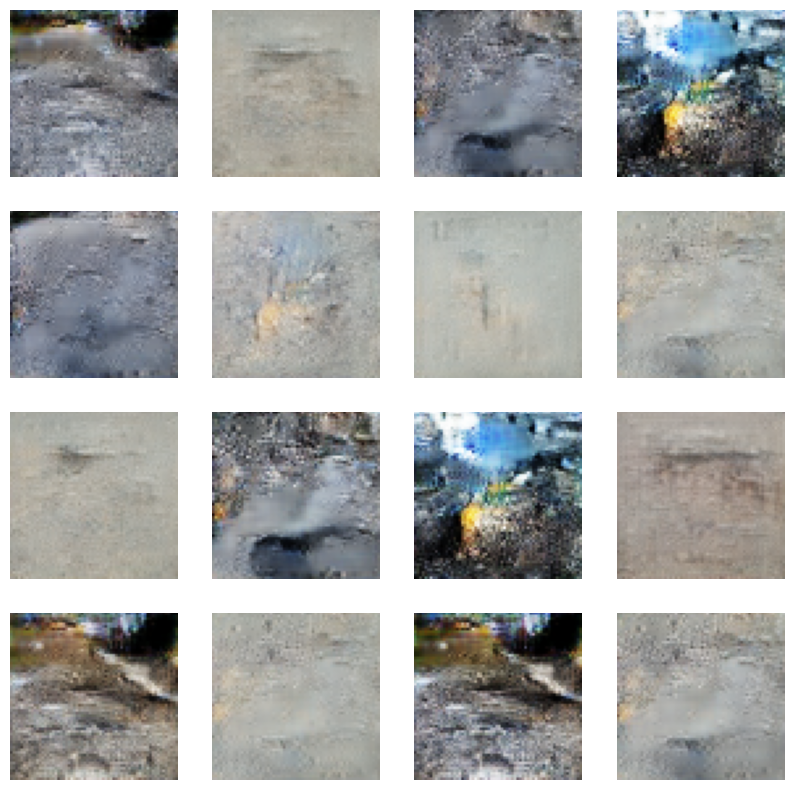

In [36]:
train(train_dataset, num_epochs, save_every = 10)

# Final GAN Output Image

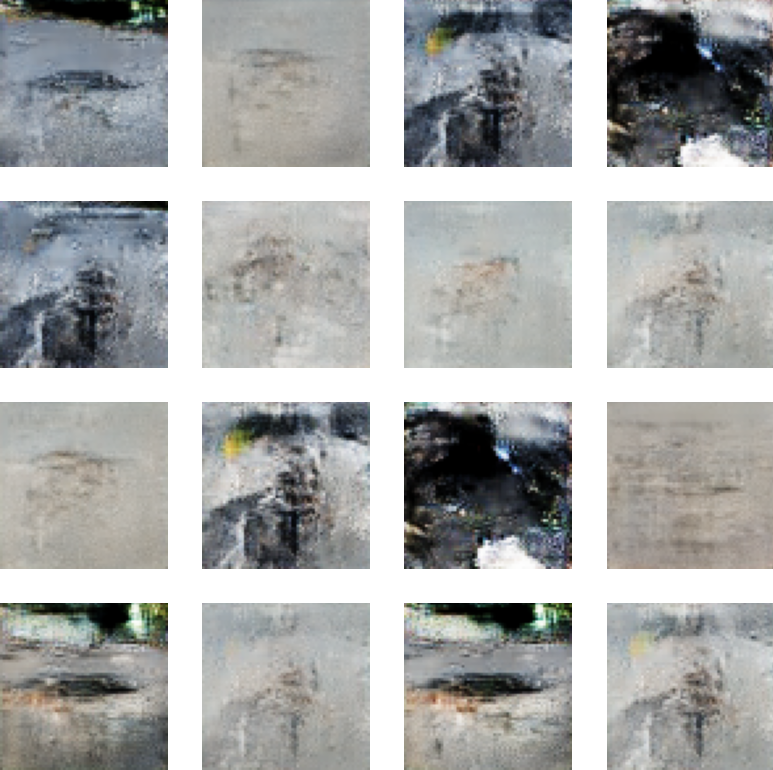

In [41]:
Image.open('figures/gan/pothole_0100.png')